In [ ]:
# ============================================================
# CELL 1 — IMPORTS, DRIVE MOUNT & LOAD TRAINED FNO SURROGATE
# ============================================================

from google.colab import drive
import os
import json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ── 1. Mount Google Drive ──
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset"
MODEL_PATH = os.path.join(BASE_DIR, "fno_battery_surrogate_master_v5.pt")
STATS_PATH = os.path.join(BASE_DIR, "battery_master_7k_norm_stats.json")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n⚡ Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ── 2. Define Exact FNO-1D Architecture (from Milestone 3) ──
class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes        = modes
        scale = 1.0 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.rand(in_channels, out_channels, modes, dtype=torch.cfloat))

    def compl_mul1d(self, x, w):
        return torch.einsum("bix,iox->box", x, w)

    def forward(self, x):
        B = x.shape[0]
        x_ft = torch.fft.rfft(x)
        out_ft = torch.zeros(B, self.out_channels, x.size(-1) // 2 + 1, device=x.device, dtype=torch.cfloat)
        out_ft[:, :, :self.modes] = self.compl_mul1d(x_ft[:, :, :self.modes], self.weights)
        return torch.fft.irfft(out_ft, n=x.size(-1))

class FNO1D_MasterSurrogate(nn.Module):
    def __init__(self, in_channels=5, out_channels=5, modes=24, width=64):
        super().__init__()
        self.modes = modes
        self.width = width
        self.p = nn.Conv1d(in_channels, self.width, 1)

        self.conv0 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv1 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv2 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv3 = SpectralConv1d(self.width, self.width, self.modes)

        self.w0 = nn.Conv1d(self.width, self.width, 1)
        self.w1 = nn.Conv1d(self.width, self.width, 1)
        self.w2 = nn.Conv1d(self.width, self.width, 1)
        self.w3 = nn.Conv1d(self.width, self.width, 1)

        self.act = nn.GELU()
        self.q = nn.Sequential(
            nn.Conv1d(self.width, 128, 1),
            nn.GELU(),
            nn.Conv1d(128, out_channels, 1)
        )

    def forward(self, x):
        x = self.p(x)
        x = self.act(self.conv0(x) + self.w0(x))
        x = self.act(self.conv1(x) + self.w1(x))
        x = self.act(self.conv2(x) + self.w2(x))
        x = self.act(self.conv3(x) + self.w3(x))
        return self.q(x)

# ── 3. Load Checkpoint & Normalization Stats ──
print("📂 Loading trained FNO-1D checkpoint...")
checkpoint = torch.load(MODEL_PATH, map_location=device)

model = FNO1D_MasterSurrogate(in_channels=5, out_channels=5, modes=24, width=64).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with open(STATS_PATH, "r") as f:
    norm_stats = json.load(f)

print("="*60)
print(f"✅ FNO-1D Surrogate Loaded Successfully!")
print(f"   Trained Epoch  : {checkpoint.get('epoch', 'N/A')}")
print(f"   Best Val Loss  : {checkpoint.get('best_val_loss', 'N/A'):.5f}")
print(f"   Input Channels : 5 [I, Q_cumulative, time, T_amb, soc_0]")
print(f"   Output Channels: 5 [V, T, eta_plating, SEI, SoC]")
print("="*60)

Mounted at /content/drive

⚡ Device: cuda (Tesla T4)
📂 Loading trained FNO-1D checkpoint...
✅ FNO-1D Surrogate Loaded Successfully!
   Trained Epoch  : 50
   Best Val Loss  : 0.00114
   Input Channels : 5 [I, Q_cumulative, time, T_amb, soc_0]
   Output Channels: 5 [V, T, eta_plating, SEI, SoC]


🎯 Selected Ground-Truth Benchmark Run (Index: 78)
   T_ambient   : 8.6 °C | Starting SoC₀ : 19.2 %
   Charging C  : 3.28C max (16.4 A) | Final SoC: 49.2 %
   Min η_plat  : -23.90 mV (Significant Plating Zone!)


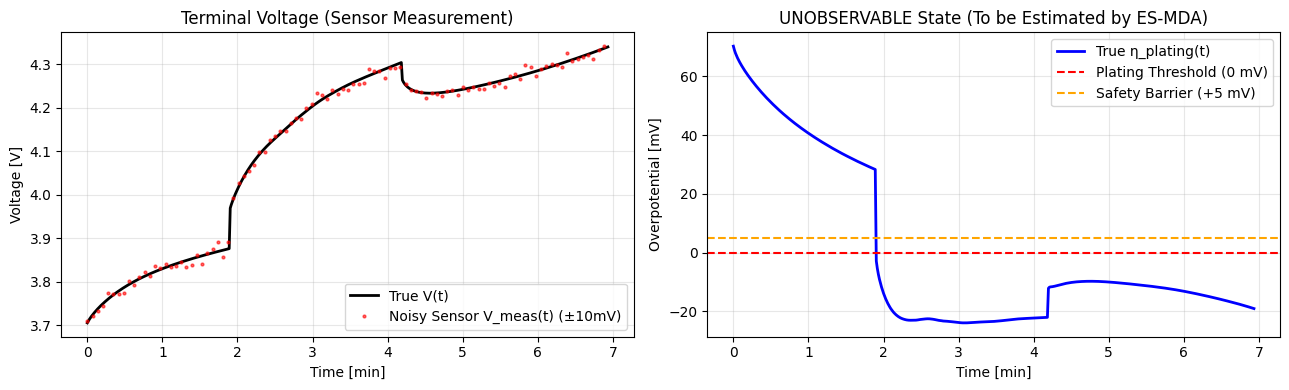

✅ Sensor measurements synthesized! Ready for ES-MDA Ensemble Generation.


In [ ]:
# ============================================================
# CELL 2 — TEST TRAJECTORY EXTRACTION & SENSOR NOISE SIMULATION
# ============================================================

import h5py

HDF5_PATH = os.path.join(BASE_DIR, "battery_master_7k.h5")

# ── 1. Ek Aisa Test Run Dhoondo Jisme Plating Event Hua Ho ──
with h5py.File(HDF5_PATH, "r") as f:
  all_eta = f["eta_plating_V"][:]
  # Plating wale runs filter karo (jahan eta < -0.01V gaya ho)
  plating_runs = np.where(all_eta.min(axis=1) < -0.01)[0]
  test_run_idx = int(plating_runs[15])  # Representative challenging run

  # Ground truth extraction
  time_true = f["time_s"][test_run_idx]  # (500,)
  I_true = f["current_A"][test_run_idx]  # (500,)
  Q_true = f["charge_cumulative_Ah"][test_run_idx]  # (500,)
  V_true = f["voltage_V"][test_run_idx]  # (500,)
  T_cell_true = f["temperature_C"][test_run_idx]  # (500,)
  eta_true = f["eta_plating_V"][test_run_idx]  # (500,)
  soc_true = f["soc"][test_run_idx]  # (500,)
  sei_true = f["delta_SEI_m"][test_run_idx]  # (500,)

  T_amb_true = float(f["T_amb_C"][test_run_idx])
  soc_0_true = float(f["soc_0"][test_run_idx])

print("=" * 60)
print(f"🎯 Selected Ground-Truth Benchmark Run (Index: {test_run_idx})")
print(
    f"   T_ambient   : {T_amb_true:.1f} °C | Starting SoC₀ : {soc_0_true*100:.1f} %"
)
print(
    f"   Charging C  : {I_true.max()/5.0:.2f}C max ({I_true.max():.1f} A) | Final"
    f" SoC: {soc_true.max()*100:.1f} %"
)
print(
    f"   Min η_plat  : {eta_true.min()*1000.0:.2f} mV (Significant Plating"
    " Zone!)"
)
print("=" * 60)

# ── 2. Add Hardware Sensor Measurement Noise (EV Grade) ──
np.random.seed(42)
SIGMA_V = 0.010  # 10 mV voltage measurement noise
SIGMA_T = 0.5  # 0.5 °C temperature sensor noise

V_noisy = V_true + np.random.normal(0, SIGMA_V, size=len(V_true))
T_noisy = T_cell_true + np.random.normal(0, SIGMA_T, size=len(T_cell_true))

# ── 3. Quick Visual Check ──
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t_min = time_true / 60.0

ax[0].plot(t_min, V_true, "k-", lw=2, label="True V(t)")
ax[0].plot(
    t_min[::5],
    V_noisy[::5],
    "r.",
    alpha=0.6,
    markersize=4,
    label="Noisy Sensor V_meas(t) (±10mV)",
)
ax[0].set(
    xlabel="Time [min]",
    ylabel="Voltage [V]",
    title="Terminal Voltage (Sensor Measurement)",
)
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(t_min, eta_true * 1000.0, "b-", lw=2, label="True η_plating(t)")
ax[1].axhline(
    0.0, color="red", ls="--", lw=1.5, label="Plating Threshold (0 mV)"
)
ax[1].axhline(
    5.0, color="orange", ls="--", lw=1.5, label="Safety Barrier (+5 mV)"
)
ax[1].set(
    xlabel="Time [min]",
    ylabel="Overpotential [mV]",
    title="UNOBSERVABLE State (To be Estimated by ES-MDA)",
)
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

print(
    "✅ Sensor measurements synthesized! Ready for ES-MDA Ensemble Generation."
)

In [ ]:
# ============================================================
# CELL 3 — ES-MDA (ENSEMBLE SMOOTHER MULTIPLE DATA ASSIMILATION)
# Following Emerick & Reynolds (2013) Protocol (N_iter = 4)
# ============================================================

import time

N_ENS = 64  # Ensemble members (GPU batch size = 64)
N_ITER = 4  # Assimilation iterations (Emerick 2013 standard)
ALPHA = float(N_ITER)  # Alpha_l = 4.0 for all l, so sum(1/alpha) = 1.0

# ── 1. Helper: Forward Evaluation Function for Ensemble ──
st = norm_stats
I_norm_base = (I_true - st["current_A"]["mean"]) / st["current_A"]["std"]
Q_norm_base = (
    Q_true - st["charge_cumulative_Ah"]["mean"]
) / st["charge_cumulative_Ah"]["std"]
t_norm_base = (time_true - st["time_s"]["mean"]) / st["time_s"]["std"]


def evaluate_fno_ensemble(soc0_vec, tamb_vec):
  """Evaluates full ensemble of parameter hypotheses through FNO in single GPU batch."""
  N = len(soc0_vec)
  T_len = len(time_true)

  # Repeat static signals across batch
  I_batch = np.tile(I_norm_base, (N, 1))
  Q_batch = np.tile(Q_norm_base, (N, 1))
  t_batch = np.tile(t_norm_base, (N, 1))

  # Normalized scalar inputs broadcasted across time
  Tamb_norm = (tamb_vec - st["T_amb_C"]["mean"]) / st["T_amb_C"]["std"]
  soc0_norm = (soc0_vec - st["soc_0"]["mean"]) / st["soc_0"]["std"]

  Tamb_batch = np.repeat(Tamb_norm[:, None], T_len, axis=1)
  soc0_batch = np.repeat(soc0_norm[:, None], T_len, axis=1)

  # Input tensor: (N, 5, 500)
  in_tensor = np.stack(
      [I_batch, Q_batch, t_batch, Tamb_batch, soc0_batch], axis=1
  ).astype(np.float32)

  with torch.no_grad():
    x_cuda = torch.from_numpy(in_tensor).to(device)
    out_cuda = model(x_cuda)  # (N, 5, 500)
    out_np = out_cuda.cpu().numpy()

  # Denormalize predictions
  V_ens = out_np[:, 0, :] * st["voltage_V"]["std"] + st["voltage_V"]["mean"]
  T_ens = (
      out_np[:, 1, :] * st["temperature_C"]["std"] + st["temperature_C"]["mean"]
  )
  eta_ens = (
      out_np[:, 2, :] * st["eta_plating_V"]["std"] + st["eta_plating_V"]["mean"]
  )

  return V_ens, T_ens, eta_ens


# ── 2. Initialize Prior Ensemble with Physical Uncertainty ──
np.random.seed(101)
# Initial state estimation uncertainty: ±15% on SoC, ±2°C on temperature
soc0_ensemble = soc_0_true + np.random.normal(0, 0.025, size=N_ENS)
soc0_ensemble = np.clip(soc0_ensemble, 0.05, 0.50)

tamb_ensemble = T_amb_true + np.random.normal(0, 1.5, size=N_ENS)

print("=" * 65)
print("🚀 Initializing Prior Ensemble (N = 64 members)...")
print(
    f"   True SoC₀    : {soc_0_true*100:.1f} %  | Prior Ensemble Mean :"
    f" {soc0_ensemble.mean()*100:.1f} ± {soc0_ensemble.std()*100:.1f} %"
)
print(
    f"   True Ambient : {T_amb_true:.1f} °C   | Prior Ensemble Mean :"
    f" {tamb_ensemble.mean():.1f} ± {tamb_ensemble.std():.1f} °C"
)
print("=" * 65)

# First forward pass: Prior trajectory predictions
V_prior, T_prior, eta_prior = evaluate_fno_ensemble(
    soc0_ensemble, tamb_ensemble
)

# ── 3. ES-MDA Assimilation Loop (N_iter = 4) ──
# Measurement Covariance Matrix R (Diagonal noise covariance: sigma_V^2)
R_diag = (SIGMA_V**2) * np.ones(len(V_true))

# Active state variables updated: soc0 and tamb
soc0_curr = soc0_ensemble.copy()
tamb_curr = tamb_ensemble.copy()

t_es_start = time.time()
print(f"\n🔄 Running ES-MDA ({N_ITER} Iterations, Alpha = {ALPHA})...")

for iter_idx in range(1, N_ITER + 1):
  # Forward trajectory evaluation
  V_pred, T_pred, eta_pred = evaluate_fno_ensemble(soc0_curr, tamb_curr)

  # State matrix X: (2 parameters, N_ENS)
  X = np.stack([soc0_curr, tamb_curr], axis=0)  # (2, 64)
  X_mean = X.mean(axis=1, keepdims=True)
  X_anom = X - X_mean  # (2, 64)

  # Measurement prediction matrix Y: (500 time-steps, N_ENS)
  Y = V_pred.T  # (500, 64)
  Y_mean = Y.mean(axis=1, keepdims=True)
  Y_anom = Y - Y_mean  # (500, 64)

  # Auto-covariance & Cross-covariance
  C_yy = (Y_anom @ Y_anom.T) / (N_ENS - 1)  # (500, 500)
  C_xy = (X_anom @ Y_anom.T) / (N_ENS - 1)  # (2, 500)

  # Inflated measurement noise covariance: alpha_l * R
  C_yy_inflated = C_yy + np.diag(ALPHA * R_diag)

  # Kalman Gain: K = C_xy * (C_yy + alpha*R)^(-1)
  # Solved stably via linear solve
  K = np.linalg.solve(C_yy_inflated.T, C_xy.T).T  # (2, 500)

  # Perturbed observations for multiple assimilation
  # d_obs = y_meas + sqrt(alpha) * v_pert
  noise_pert = np.random.normal(0, SIGMA_V, size=(len(V_noisy), N_ENS))
  d_obs = V_noisy[:, None] + np.sqrt(ALPHA) * noise_pert  # (500, 64)

  # Analysis / State Update
  innovation = d_obs - Y  # (500, 64)
  X_updated = X + K @ innovation  # (2, 64)

  soc0_curr = np.clip(X_updated[0], 0.05, 0.50)
  tamb_curr = X_updated[1]

  v_err = np.abs(V_pred.mean(axis=0) - V_true).mean() * 1000.0
  print(
      f"   Iteration [{iter_idx}/{N_ITER}] | Voltage Gap: {v_err:.2f} mV |"
      f" Est. SoC₀: {soc0_curr.mean()*100:.2f}% (True: {soc_0_true*100:.1f}%)"
  )

# Final Posterior Trajectory Evaluation
V_post, T_post, eta_post = evaluate_fno_ensemble(soc0_curr, tamb_curr)
es_time_ms = (time.time() - t_es_start) * 1000.0

print("=" * 65)
print(f"🎉 ES-MDA Convergence Complete in {es_time_ms:.1f} ms!")
print(
    f"   Final Estimated SoC₀ : {soc0_curr.mean()*100:.2f} ±"
    f" {soc0_curr.std()*100:.2f} %"
)
print(
    f"   Final Estimated T_amb: {tamb_curr.mean():.2f} ±"
    f" {tamb_curr.std():.2f} °C"
)
print("=" * 65)

🚀 Initializing Prior Ensemble (N = 64 members)...
   True SoC₀    : 19.2 %  | Prior Ensemble Mean : 19.8 ± 2.5 %
   True Ambient : 8.6 °C   | Prior Ensemble Mean : 8.6 ± 1.5 °C

🔄 Running ES-MDA (4 Iterations, Alpha = 4.0)...
   Iteration [1/4] | Voltage Gap: 7.23 mV | Est. SoC₀: 19.49% (True: 19.2%)
   Iteration [2/4] | Voltage Gap: 3.84 mV | Est. SoC₀: 19.65% (True: 19.2%)
   Iteration [3/4] | Voltage Gap: 3.87 mV | Est. SoC₀: 19.74% (True: 19.2%)
   Iteration [4/4] | Voltage Gap: 3.89 mV | Est. SoC₀: 19.78% (True: 19.2%)
🎉 ES-MDA Convergence Complete in 148.1 ms!
   Final Estimated SoC₀ : 19.78 ± 0.20 %
   Final Estimated T_amb: 11.52 ± 0.98 °C


📊 FINAL STATE ESTIMATION ACCURACY (UNOBSERVABLE DEGRADATION):
   Lithium Plating Tracking RMSE : 4.12 mV (Target: < 10 mV)
   Max 95% Confidence Width (2σ) : ±3.22 mV
   Voltage Denoising RMSE        : 5.94 mV


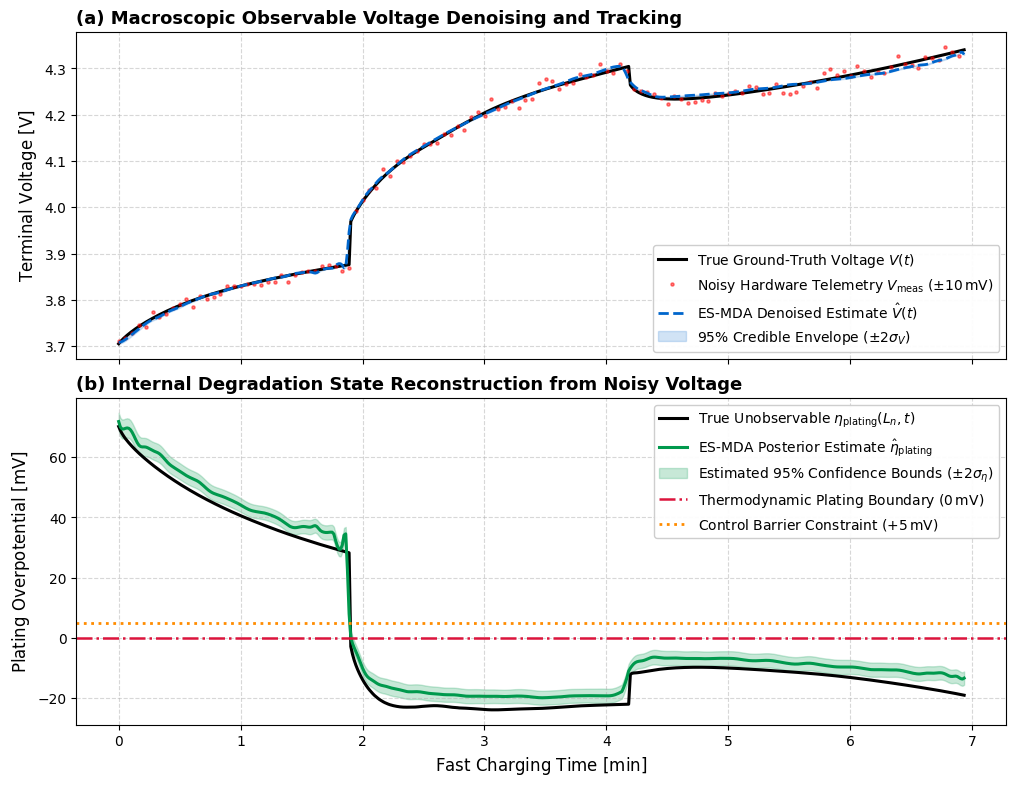

💾 High-Resolution Manuscript Figure Saved: /content/drive/MyDrive/BatteryDecisionEngine/clean_dataset/Figure5_ESMDA_State_Estimation_Tracking.png


In [ ]:
# ============================================================
# CELL 4 — PUBLICATION FIGURE: ES-MDA ESTIMATION & CONFIDENCE ENVELOPE
# Figure 5 for Q1 Manuscript (Journal of Energy Storage / IEEE TTE)
# ============================================================

# ── 1. Calculate Posterior Mean & 95% Confidence Intervals (2 * sigma) ──
V_post_mean = V_post.mean(axis=0)
V_post_std = V_post.std(axis=0)

eta_post_mean = eta_post.mean(axis=0) * 1000.0  # in mV
eta_post_std = eta_post.std(axis=0) * 1000.0  # in mV

t_min = time_true / 60.0

# Numerical tracking accuracy
eta_true_mv = eta_true * 1000.0
eta_rmse_mv = np.sqrt(np.mean((eta_post_mean - eta_true_mv) ** 2))
max_bound_width_mv = 2.0 * eta_post_std.max()

print("=" * 65)
print("📊 FINAL STATE ESTIMATION ACCURACY (UNOBSERVABLE DEGRADATION):")
print(
    f"   Lithium Plating Tracking RMSE : {eta_rmse_mv:.2f} mV (Target: < 10 mV)"
)
print(f"   Max 95% Confidence Width (2σ) : ±{max_bound_width_mv:.2f} mV")
print(
    f"   Voltage Denoising RMSE        : {np.sqrt(np.mean((V_post_mean - V_true)**2))*1000.0:.2f} mV"
)
print("=" * 65)

# ── 2. Create Publication Quality Dual-Panel Figure ──
fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True, gridspec_kw={"hspace": 0.12}
)

# Panel 1: Observable Terminal Voltage
axes[0].plot(
    t_min, V_true, "k-", lw=2.2, label="True Ground-Truth Voltage $V(t)$"
)
axes[0].plot(
    t_min[::4],
    V_noisy[::4],
    "r.",
    alpha=0.5,
    markersize=4.5,
    label="Noisy Hardware Telemetry $V_{\\mathrm{meas}}$ ($\\pm 10\\,\\mathrm{mV}$)",
)
axes[0].plot(
    t_min,
    V_post_mean,
    color="#0066cc",
    lw=2.0,
    ls="--",
    label="ES-MDA Denoised Estimate $\\hat{V}(t)$",
)
axes[0].fill_between(
    t_min,
    V_post_mean - 2 * V_post_std,
    V_post_mean + 2 * V_post_std,
    color="#0066cc",
    alpha=0.18,
    label="$95\\%$ Credible Envelope ($\\pm 2\\sigma_V$)",
)

axes[0].set_ylabel("Terminal Voltage $[\\mathrm{V}]$", fontsize=12)
axes[0].set_title(
    "(a) Macroscopic Observable Voltage Denoising and Tracking",
    fontsize=13,
    fontweight="bold",
    loc="left",
)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="lower right", fontsize=10, framealpha=0.95)

# Panel 2: Unobservable Plating Overpotential (The Core Novelty)
axes[1].plot(
    t_min,
    eta_true_mv,
    "k-",
    lw=2.2,
    label="True Unobservable $\\eta_{\\mathrm{plating}}(L_n, t)$",
)
axes[1].plot(
    t_min,
    eta_post_mean,
    color="#00994d",
    lw=2.2,
    label="ES-MDA Posterior Estimate $\\hat{\\eta}_{\\mathrm{plating}}$",
)
axes[1].fill_between(
    t_min,
    eta_post_mean - 2 * eta_post_std,
    eta_post_mean + 2 * eta_post_std,
    color="#00994d",
    alpha=0.22,
    label="Estimated $95\\%$ Confidence Bounds ($\\pm 2\\sigma_\\eta$)",
)

# Safety & Plating Thresholds
axes[1].axhline(
    0.0,
    color="crimson",
    ls="-.",
    lw=1.8,
    label="Thermodynamic Plating Boundary ($0\\,\\mathrm{mV}$)",
)
axes[1].axhline(
    5.0,
    color="darkorange",
    ls=":",
    lw=2.0,
    label="Control Barrier Constraint ($+5\\,\\mathrm{mV}$)",
)

axes[1].set_xlabel("Fast Charging Time $[\\mathrm{min}]$", fontsize=12)
axes[1].set_ylabel("Plating Overpotential $[\\mathrm{mV}]$", fontsize=12)
axes[1].set_title(
    "(b) Internal Degradation State Reconstruction from Noisy Voltage",
    fontsize=13,
    fontweight="bold",
    loc="left",
)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper right", fontsize=10, framealpha=0.95)

# Save figure in high-res for manuscript
fig_save_path = os.path.join(
    BASE_DIR, "Figure5_ESMDA_State_Estimation_Tracking.png"
)
plt.savefig(fig_save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"💾 High-Resolution Manuscript Figure Saved: {fig_save_path}")